# Notebook 01 · Pre-Processing Data

| | |
|---|---|
| Nama | Dimas Fadilah Permana R |
| NIM | 25.55.1752 |
| Program Studi | S2 PJJ Informatika, Universitas AMIKOM Yogyakarta |
| Pembimbing | Prof. Dr. Ema Utami, S.Si., M.Kom. |
| Dataset | Large-scale Short-Video Dataset, Kuaishou (Shang dkk., 2025, Tsinghua University) |

Variabel yang dipakai di seluruh penelitian:

* **X (input):** transkrip ASR yang sudah dibersihkan (`text_clean`) dan durasi video (`duration_norm`).
* **Y (target):** retensi tontonan (`retensi`), yaitu rata-rata bagian durasi video yang ditonton penonton.
  `watch_time` hanya dipakai untuk menghitung Y, tidak pernah menjadi input model.

### Alur notebook

1. Persiapan dan konfigurasi
2. Memuat tiga sumber data mentah (interaksi, kategori, transkrip ASR)
3. Membersihkan duplikasi interaksi
4. Menghitung target retensi per video
5. Menggabungkan sumber data dan menerapkan filter kualitas
6. Membersihkan teks transkrip
7. Membagi data dan menormalkan tanpa kebocoran
8. Profil dataset (struktur, statistik, contoh data, visualisasi)
9. Menyimpan data dan ringkasan

### Perubahan dari versi yang dipakai pada naskah pertama

1. **Duplikasi interaksi dibersihkan.** Pada file interaksi, satu kejadian menonton tercatat berulang
   kali (satu baris untuk setiap tag video dan setiap level kategori). Versi lama menghitung baris ini
   sebagai jumlah tayangan, sehingga filter "minimal 5 views" meloloskan banyak video yang sebenarnya
   hanya ditonton satu atau dua orang. Sekarang setiap interaksi dihitung satu kali.
2. **Filter memakai jumlah penonton unik.**
3. **Target dipakai langsung dalam skala 0 sampai 1**, tanpa log-transform dan MinMax, agar mudah dibaca:
   retensi 0,62 berarti rata-rata penonton menonton 62% durasi video.
4. **Dua target pembanding ditambahkan** untuk analisis sensitivitas: retensi yang dikontrol durasi
   dan retensi tanpa pemotongan nilai di atas 1.
5. **Profil dataset, contoh data, dan jejak data** disimpan sebagai tabel.
6. **Partisi acak dan partisi per kreator** dibuat dalam satu kali jalan.

---
# Persiapan Lingkungan
### Deteksi lingkungan (Kaggle, Colab, atau laptop)
Notebook ini bisa dijalankan di tiga tempat tanpa mengubah kode.

In [1]:
import os

DI_KAGGLE = os.path.exists('/kaggle/input') or 'KAGGLE_KERNEL_RUN_TYPE' in os.environ
IN_COLAB = (not DI_KAGGLE) and (os.path.exists('/var/colab/hostname') or 'COLAB_RELEASE_TAG' in os.environ)

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
LINGKUNGAN = 'Kaggle' if DI_KAGGLE else 'Colab' if IN_COLAB else 'Lokal'
print(f"Lingkungan: {LINGKUNGAN}")

Lingkungan: Kaggle


### Pemasangan pustaka
`emoji` dipakai untuk mengubah emoji menjadi teks. Pustaka lain sudah tersedia di Kaggle dan Colab.
Di Kaggle, pastikan **Internet** dinyalakan di panel Settings agar pemasangan berhasil.

In [2]:
if IN_COLAB or DI_KAGGLE:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "emoji"], check=False)
    print("Pemasangan pustaka selesai.")
else:
    print("Lewati pemasangan (pustaka sudah ada).")

Pemasangan pustaka selesai.


### Impor Pustaka

In [3]:
import re, zipfile, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji

from sklearn.model_selection import train_test_split, GroupShuffleSplit
from sklearn.preprocessing import MinMaxScaler
from sklearn.isotonic import IsotonicRegression
from scipy.stats import spearmanr

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 90)
plt.rcParams['figure.dpi'] = 110
sns.set_style('whitegrid')
print("Pustaka dimuat.")

Pustaka dimuat.


### Konfigurasi

Semua path dan ambang keputusan dikumpulkan di satu sel ini.

| Berkas mentah | Isi | Peran |
|---|---|---|
| `interaction_sampled.csv` | Satu baris per kejadian menonton (user, video, waktu tonton, durasi, dll.) | Sumber target Y dan durasi |
| `categories_cn_en (1).csv` | Peta kategori video | Hanya untuk deskripsi data |
| `Tesis_Dimas.zip` berisi folder `asr_en/` | Transkrip ASR bahasa Inggris, satu berkas per video | Sumber fitur teks |

Lokasi ketiga berkas dicari otomatis di dalam folder data, jadi nama folder Kaggle Dataset tidak
berpengaruh. Kaggle mengekstrak ZIP secara otomatis saat diunggah; notebook bisa membaca transkrip
baik dari ZIP maupun dari folder `asr_en/` hasil ekstraksi.

| Ambang | Nilai | Alasan |
|---|---|---|
| Durasi | 5 sampai 120 detik | Format video pendek |
| Penonton unik | minimal 5 | Retensi dari 1 sampai 2 penonton terlalu bising (lihat Tahap 4.2) |
| Panjang transkrip | minimal 5 kata | Transkrip yang lebih pendek tidak membawa informasi teks |
| Pembagian data | 70/15/15 | Latih / validasi / uji |

In [4]:
SEED = 42
np.random.seed(SEED)

# Lokasi data mentah dan folder keluaran
if DI_KAGGLE:
    DATA_ROOT, OUT_BASE = '/kaggle/input', '/kaggle/working'
elif IN_COLAB:
    DATA_ROOT = '/content/drive/MyDrive/dataset_tsinghua'
    OUT_BASE = '/content/drive/MyDrive/Tesis_Dimas/dataset_tsinghua'
else:
    DATA_ROOT = os.environ.get('TESIS_DATA_ROOT', './data_mentah')
    OUT_BASE = os.environ.get('TESIS_OUT_BASE', './hasil')

import fnmatch

def cari_berkas(akar, pola):
    # telusuri semua subfolder (termasuk symlink), kembalikan berkas pertama yang cocok dengan pola
    for folder, subfolder, berkas in os.walk(akar, followlinks=True):
        subfolder.sort()
        for nama in sorted(berkas):
            if fnmatch.fnmatch(nama, pola):
                return os.path.join(folder, nama)
    return None

def cari_folder(akar, nama_folder, isi=None):
    # folder bernama nama_folder (dan berisi 'isi', bila diberikan)
    for folder, subfolder, berkas in os.walk(akar, followlinks=True):
        subfolder.sort()
        if os.path.basename(folder) == nama_folder and (isi is None or isi in subfolder + berkas):
            return folder
    return None

def tampilkan_isi(akar, kedalaman=3):
    # dipakai bila ada berkas yang tidak ditemukan, untuk melihat struktur folder input
    print(f"Isi {akar}:")
    for folder, subfolder, berkas in os.walk(akar, followlinks=True):
        tingkat = folder[len(akar):].count(os.sep)
        print('   ' * tingkat + (os.path.basename(folder) or akar) + f'/  ({len(berkas)} berkas)')
        if tingkat >= kedalaman - 1:
            subfolder[:] = []
        for b in sorted(berkas)[:4]:
            print('   ' * (tingkat + 1) + b)

# Nama berkas boleh sedikit berbeda, misalnya "interaction_sampled (1).csv"
INTERACTION_PATH = cari_berkas(DATA_ROOT, 'interaction_sampled*.csv')
CATEGORY_PATH = cari_berkas(DATA_ROOT, 'categories_cn_en*.csv')
ZIP_PATH = cari_berkas(DATA_ROOT, 'Tesis_Dimas*.zip')            # bila ZIP masih utuh
ASR_DIR = None if ZIP_PATH else cari_folder(DATA_ROOT, 'asr_en')  # bila ZIP sudah diekstrak

# Dua folder keluaran: partisi acak (utama) dan partisi per kreator (uji ketahanan)
OUT_DIR = {'random': os.path.join(OUT_BASE, 'final_revisi'),
           'author': os.path.join(OUT_BASE, 'final_revisi_authorsplit')}
for _d in OUT_DIR.values():
    os.makedirs(_d, exist_ok=True)

# Satu interaksi = satu user menonton satu video pada satu waktu tayang
KUNCI_INTERAKSI = ['user_id', 'pid', 'exposed_time']

DUR_MIN, DUR_MAX = 5, 120      # detik
MIN_PENONTON = 5               # penonton unik per video
MIN_KATA = 5                   # kata per transkrip
UKURAN_VAL, UKURAN_TEST = 0.15, 0.15

for nama, path in [('Interaksi', INTERACTION_PATH), ('Kategori', CATEGORY_PATH),
                   ('Transkrip', ZIP_PATH or ASR_DIR)]:
    print(f"{nama:10s}: {path or 'TIDAK DITEMUKAN'}")
if not (INTERACTION_PATH and CATEGORY_PATH and (ZIP_PATH or ASR_DIR)):
    tampilkan_isi(DATA_ROOT)
    raise FileNotFoundError("Ada berkas data mentah yang belum ditemukan. Di Kaggle, pastikan Dataset "
                            "sudah ditambahkan lewat Add Input (panel kanan, bagian Input).")
print(f"\nKeluaran  : {OUT_DIR['random']}\n            {OUT_DIR['author']}")
print(f"Filter    : durasi {DUR_MIN}-{DUR_MAX} dtk, penonton unik >= {MIN_PENONTON}, kata >= {MIN_KATA}")

Interaksi : /kaggle/input/datasets/dimasfadilahamikom/tesis-dimas-data-mentah/interaction_sampled (1).csv
Kategori  : /kaggle/input/datasets/dimasfadilahamikom/tesis-dimas-data-mentah/categories_cn_en.csv
Transkrip : /kaggle/input/datasets/dimasfadilahamikom/tesis-dimas-data-mentah/Tesis_Dimas/Tesis_Dimas/asr_en

Keluaran  : /kaggle/working/final_revisi
            /kaggle/working/final_revisi_authorsplit
Filter    : durasi 5-120 dtk, penonton unik >= 5, kata >= 5


---
# TAHAP 1 · Import Data Mentah
### 1.1 Data interaksi

Setiap baris berisi satu kejadian seorang user melihat satu video. Kolom yang dipakai: `user_id`,
`pid` (id video), `exposed_time` (waktu video ditayangkan ke user), `watch_time` (detik ditonton),
`duration` (durasi video), `author_id` (kreator), dan `root_id` (kategori utama).

In [5]:
df_interaction = pd.read_csv(INTERACTION_PATH)
print(f"Ukuran     : {df_interaction.shape[0]:,} baris x {df_interaction.shape[1]} kolom")
print(f"Video unik : {df_interaction['pid'].nunique():,}")
print(f"User unik  : {df_interaction['user_id'].nunique():,}")
print(f"\nKolom: {list(df_interaction.columns)}")

kolom_lihat = ['user_id', 'pid', 'exposed_time', 'watch_time', 'duration', 'author_id', 'root_id']
display(df_interaction[kolom_lihat].head())

Ukuran     : 794,053 baris x 28 kolom
Video unik : 31,496
User unik  : 6,654

Kolom: ['user_id', 'pid', 'author_id', 'category_id', 'category_level', 'parent_id', 'root_id', 'exposed_time', 'author_fans_count', 'watch_time', 'duration', 'cvm_like', 'click', 'comment', 'follow', 'collect', 'forward', 'hate', 'tag_name', 'title', 'p_hour', 'p_date', 'gender', 'age', 'mod_price', 'fre_city', 'fre_community_type', 'fre_city_level']


,user_id,pid,exposed_time,watch_time,duration,author_id,root_id
0,7313,36548,1663339704,156,151.400,2826468046,22
1,7313,36548,1663339704,156,151.400,2826468046,22
2,7313,99826,1663339410,100,107.419,2235609401,30
3,7313,99826,1663339410,100,107.419,2235609401,30
4,7313,99826,1663339410,100,107.419,2235609401,30


### 1.2 Data kategori
Hanya kategori level teratas (`category_level == 1`) yang dipakai, untuk memberi nama kategori pada
setiap video. Kategori bukan input model.

In [6]:
df_category = pd.read_csv(CATEGORY_PATH)
cat_root = (df_category[df_category['category_level'] == 1][['category_id', 'category_name_en']]
            .rename(columns={'category_id': 'category_root', 'category_name_en': 'category_root_name'}))
print(f"Kategori level 1: {len(cat_root)}")
display(cat_root.head())

Kategori level 1: 36


,category_root,category_root_name
25,12,gourmet
88,7,movement
126,5,wear it
141,20,quadratic
172,25,parent-child


### 1.3 Transkrip ASR
Satu berkas `.txt` per video di folder `asr_en/`, dengan nama berkas sama dengan `pid`. Transkrip
dibaca langsung dari ZIP bila ZIP masih utuh (Colab), atau dari folder hasil ekstraksi (Kaggle).

In [7]:
asr = {}
def simpan_transkrip(nama_berkas, isi):
    pid = os.path.basename(nama_berkas)[:-4]
    teks = isi.decode('utf-8', errors='ignore').strip()
    if pid.isdigit() and teks:
        asr[int(pid)] = teks

if ZIP_PATH:
    with zipfile.ZipFile(ZIP_PATH) as zf:
        files = [f for f in zf.namelist() if 'asr_en/' in f and f.endswith('.txt')]
        for f in files:
            simpan_transkrip(f, zf.read(f))
else:
    files = [os.path.join(ASR_DIR, f) for f in os.listdir(ASR_DIR) if f.endswith('.txt')]
    for f in files:
        with open(f, 'rb') as fp:
            simpan_transkrip(f, fp.read())

df_asr = pd.DataFrame({'pid': list(asr.keys()), 'text': list(asr.values())})
print(f"Berkas transkrip        : {len(files):,}")
print(f"Transkrip tidak kosong  : {len(df_asr):,}")
display(df_asr.head(3))

Berkas transkrip        : 153,561
Transkrip tidak kosong  : 153,491


,pid,text
0,138423,The grandmother accidentally opened the makeup box of her daughter-in-law during clean...
1,84711,"The wife of the king of Qin is here, and no one thinks of me at all. Song Xiao Niang h..."
2,75286,The dish is a bit challenging to make at home. The traditional method of cooking squid...


---
# TAHAP 2 · Membersihkan Duplikasi Interaksi

File interaksi menyimpan satu kejadian menonton dalam beberapa baris: satu baris untuk setiap tag
video dan setiap level kategori. Isi `watch_time` pada baris-baris salinan itu identik. Kalau baris
dihitung apa adanya, jumlah tayangan sebuah video menjadi berlipat.

Pada versi naskah pertama, kesalahan ini membuat filter "minimal 5 views" meloloskan video yang
sebenarnya hanya ditonton 1 sampai 3 orang. Nilai retensi per video tidak berubah (karena setiap
interaksi berlipat dengan jumlah yang hampir sama), tetapi label dari sedikit penonton sangat bising.

### 2.1 Mencari duplikasi

In [8]:
salinan = df_interaction.groupby(KUNCI_INTERAKSI).size()
print("Jumlah baris untuk satu kejadian menonton:")
print(salinan.describe().round(2).to_string())

# Contoh satu kejadian menonton yang tercatat di banyak baris
contoh_kunci = salinan[salinan == int(salinan.median())].index[0]
cocok = (df_interaction[KUNCI_INTERAKSI] == pd.Series(contoh_kunci, index=KUNCI_INTERAKSI)).all(axis=1)
contoh = df_interaction[cocok]
print(f"\nContoh: user {contoh_kunci[0]} menonton video {contoh_kunci[1]} satu kali, "
      f"tetapi tercatat {len(contoh)} baris:")
display(contoh[['user_id', 'pid', 'exposed_time', 'watch_time', 'duration',
                'tag_name', 'category_level', 'category_id']])

Jumlah baris untuk satu kejadian menonton:
count    129483.00
mean          6.13
std          10.00
min           1.00
25%           3.00
50%           6.00
75%           8.00
max         675.00

Contoh: user 1 menonton video 63980 satu kali, tetapi tercatat 6 baris:


,user_id,pid,exposed_time,watch_time,duration,tag_name,category_level,category_id
572099,1,63980,1663598611,111,112.0,综合格斗,1,7
572100,1,63980,1663598611,111,112.0,格斗,1,7
572101,1,63980,1663598611,111,112.0,快手热点,1,7
572102,1,63980,1663598611,111,112.0,综合格斗,2,128
572103,1,63980,1663598611,111,112.0,格斗,2,128
572104,1,63980,1663598611,111,112.0,快手热点,2,128


### 2.2 Menghapus duplikat
Satu interaksi didefinisikan oleh kombinasi `user_id`, `pid`, dan `exposed_time`. Sebelum menghapus
duplikat, saya memastikan bahwa `watch_time` dan `duration` memang sama pada semua salinan.

In [9]:
beda_watch = int((df_interaction.groupby(KUNCI_INTERAKSI)['watch_time'].nunique() > 1).sum())
beda_durasi = int((df_interaction.groupby('pid')['duration'].nunique() > 1).sum())
print(f"Interaksi dengan watch_time berbeda antar-salinan : {beda_watch}")
print(f"Video dengan durasi berbeda antar-baris           : {beda_durasi}")

df_int = df_interaction.drop_duplicates(KUNCI_INTERAKSI).reset_index(drop=True)
print(f"\nBaris sebelum : {len(df_interaction):,}")
print(f"Interaksi unik: {len(df_int):,} ({len(df_int) / len(df_interaction) * 100:.1f}% dari baris)")

# Dampak pada hitungan per video
baris_per_video = df_interaction.groupby('pid').size()
unik_per_video = df_int.groupby('pid').size()
penonton_per_video = df_int.groupby('pid')['user_id'].nunique()
dampak = pd.DataFrame({
    'Cara hitung': ['Baris mentah (cara lama)', 'Interaksi unik', 'Penonton unik'],
    'Median per video': [baris_per_video.median(), unik_per_video.median(), penonton_per_video.median()],
    'Video dengan >= 5': [(baris_per_video >= 5).sum(), (unik_per_video >= 5).sum(),
                          (penonton_per_video >= 5).sum()],
})
display(dampak)

Interaksi dengan watch_time berbeda antar-salinan : 0
Video dengan durasi berbeda antar-baris           : 0

Baris sebelum : 794,053
Interaksi unik: 129,483 (16.3% dari baris)


,Cara hitung,Median per video,Video dengan >= 5
0,Baris mentah (cara lama),12.0,25297
1,Interaksi unik,2.0,7565
2,Penonton unik,2.0,7474


---
# TAHAP 3 · Target Retensi per Video

Untuk interaksi ke-$j$ pada video $i$ dengan waktu tonton $w_{ij}$ detik dan durasi video $d_i$ detik:

$$r_{ij} = \min\left(\frac{w_{ij}}{d_i},\ 1\right) \qquad\qquad R_i = \frac{1}{n_i}\sum_{j=1}^{n_i} r_{ij}$$

$R_i$ adalah **retensi** video $i$ (target Y utama), dengan $n_i$ jumlah interaksi unik.
Rasio dipotong di 1 karena penonton yang menonton ulang bisa menghasilkan rasio 2, 3, atau lebih,
dan satu penonton seperti itu dapat mendominasi rata-rata video yang penontonnya sedikit. Dampak
pemotongan ini diuji dengan target pembanding `retensi_tanpa_clip` (rata-rata rasio tanpa dipotong).

Kolom lain yang dihitung per video:

| Kolom | Arti |
|---|---|
| `retensi_tanpa_clip` | Rata-rata $w_{ij}/d_i$ tanpa dipotong (target pembanding) |
| `detik_tonton` | Rata-rata detik yang ditonton, dibatasi maksimal sebesar durasi |
| `pct_tonton_ulang` | Proporsi interaksi dengan rasio di atas 1 |
| `n_tayangan`, `n_penonton` | Jumlah interaksi unik dan jumlah user unik |

In [10]:
df_int['rasio'] = df_int['watch_time'] / df_int['duration'].clip(lower=1)
df_int['rasio_clip'] = df_int['rasio'].clip(0, 1)
df_int['detik_tonton'] = np.minimum(df_int['watch_time'], df_int['duration'])
df_int['tonton_ulang'] = (df_int['rasio'] > 1).astype(float)

per_video = df_int.groupby('pid').agg(
    retensi=('rasio_clip', 'mean'),
    retensi_tanpa_clip=('rasio', 'mean'),
    detik_tonton=('detik_tonton', 'mean'),
    pct_tonton_ulang=('tonton_ulang', 'mean'),
    n_tayangan=('pid', 'size'),
    n_penonton=('user_id', 'nunique'),
    duration=('duration', 'first'),
    author_id=('author_id', 'first'),
    category_root=('root_id', 'first'),
).reset_index()

print(f"Video dengan target: {len(per_video):,}")
display(per_video.head())

Video dengan target: 31,496


,pid,retensi,retensi_tanpa_clip,detik_tonton,pct_tonton_ulang,n_tayangan,n_penonton,duration,author_id,category_root
0,1,0.520154,0.523606,7.663429,0.190476,21,21,14.733,520560003,6
1,2,0.514493,0.942029,4.733333,0.333333,3,3,9.200,1107894491,5
2,3,0.556522,0.556522,6.400000,0.000000,5,5,11.500,1107894491,5
3,4,0.693225,0.693225,15.000000,0.000000,1,1,21.638,115768959,7
4,5,0.311680,0.592125,6.316500,0.250000,4,4,20.266,50103091,4


### 3.2 Diagnostik target: pemotongan dan efek plafon (Ceiling Effect): Kondisi ketika soal atau instrumen tes terlalu mudah, sehingga hampir semua responden mendapat skor maksimal (menyentuh "plafon"). Akibatnya, tes gagal membedakan mana subjek yang benar-benar jenius/sangat mahir dan mana yang berkemampuan rata-rata

In [11]:
pct_ulang = df_int['tonton_ulang'].mean() * 100
pct_plafon = (per_video['retensi'] >= 0.999).mean() * 100
print(f"Interaksi dengan rasio > 1 (dipotong menjadi 1): {pct_ulang:.1f}%")
print(f"Video dengan retensi = 1 (plafon)               : {pct_plafon:.1f}%")
print("\nPersentil retensi (semua video sebelum filter):")
print(per_video['retensi'].quantile([.05, .25, .5, .75, .9, .95, .99]).round(3).to_string())

Interaksi dengan rasio > 1 (dipotong menjadi 1): 29.1%
Video dengan retensi = 1 (plafon)               : 12.5%

Persentil retensi (semua video sebelum filter):
0.05    0.018
0.25    0.173
0.50    0.455
0.75    0.725
0.90    1.000
0.95    1.000
0.99    1.000


---
# TAHAP 4 · Penggabungan dan Filter Kualitas
### 4.1 Menggabungkan target, transkrip, dan kategori

In [12]:
df = per_video.merge(df_asr, on='pid', how='left')
df = df.merge(cat_root, on='category_root', how='left')
df['category_root_name'] = df['category_root_name'].fillna('unknown').str.strip()
df['ada_asr'] = df['text'].notna()

def bersihkan_teks(teks):
    # huruf kecil, buang URL dan karakter kontrol, rapikan spasi, emoji menjadi teks
    if not isinstance(teks, str):
        return ''
    teks = teks.lower()
    teks = re.sub(r'https?://\S+|www\.\S+', '', teks)
    teks = re.sub(r'[\x00-\x1f\x7f-\x9f]', ' ', teks)
    teks = emoji.demojize(teks, delimiters=(' :', ': '))
    return re.sub(r'\s+', ' ', teks).strip()

df['text_clean'] = df['text'].apply(bersihkan_teks)
df['word_count'] = df['text_clean'].str.split().str.len().fillna(0).astype(int)
print(f"Video setelah penggabungan  : {len(df):,}")
print(f"Video tanpa transkrip ASR   : {(~df['ada_asr']).sum():,}")

Video setelah penggabungan  : 31,496
Video tanpa transkrip ASR   : 4


### 4.2 Sensitivitas ambang jumlah penonton

Semakin banyak penonton, semakin andal nilai retensi sebuah video, tetapi semakin sedikit video yang
tersisa. Tabel di bawah menghitung jumlah video akhir (setelah semua filter lain) untuk berbagai ambang
penonton unik. Ambang 5 dipilih sebagai kompromi: retensi dirata-rata dari minimal 5 orang, dan data
masih cukup untuk melatih model deep learning.

In [13]:
lolos_lain = (df['duration'].between(DUR_MIN, DUR_MAX) & (df['retensi'] > 0)
              & df['ada_asr'] & (df['word_count'] >= MIN_KATA))
sens = pd.DataFrame({
    'Min penonton unik': list(range(1, 11)),
    'Jumlah video akhir': [int((lolos_lain & (df['n_penonton'] >= k)).sum()) for k in range(1, 11)],
})
sens['Perkiraan data latih (70%)'] = (sens['Jumlah video akhir'] * 0.7).round().astype(int)
display(sens.style.apply(lambda r: ['background-color: #D9E2F3' if r['Min penonton unik'] == MIN_PENONTON
                                    else '' for _ in r], axis=1))

,Min penonton unik,Jumlah video akhir,Perkiraan data latih (70%)
0,1,20505,14353
1,2,14463,10124
2,3,9734,6814
3,4,6601,4621
4,5,4648,3254
5,6,3440,2408
6,7,2586,1810
7,8,2052,1436
8,9,1674,1172
9,10,1373,961


### 4.3 Menerapkan filter dan mencatat jejak data
Setiap filter dicatat jumlah video yang gugur. Tabel jejak ini masuk ke paper sebagai jumlah data
awal sampai akhir.

In [14]:
jejak = [{'Tahap': 'Video pada data interaksi', 'Jumlah video': df_interaction['pid'].nunique(),
          'Dibuang': None, 'Keterangan': f"{len(df_interaction):,} baris, {len(df_int):,} interaksi unik"}]

def catat(nama, mask, ket=''):
    global df
    dibuang = int((~mask).sum())
    df = df[mask].reset_index(drop=True)
    jejak.append({'Tahap': nama, 'Jumlah video': len(df), 'Dibuang': dibuang, 'Keterangan': ket})

catat('Memiliki transkrip ASR', df['ada_asr'])
catat(f'Durasi {DUR_MIN} sampai {DUR_MAX} detik', df['duration'].between(DUR_MIN, DUR_MAX))
catat(f'Minimal {MIN_PENONTON} penonton unik', df['n_penonton'] >= MIN_PENONTON)
catat('Retensi lebih dari 0', df['retensi'] > 0, 'semua penonton menonton 0 detik')
display(pd.DataFrame(jejak).astype({'Dibuang': 'Int64'}))

,Tahap,Jumlah video,Dibuang,Keterangan
0,Video pada data interaksi,31496,<NA>,"794,053 baris, 129,483 interaksi unik"
1,Memiliki transkrip ASR,31492,4,
2,Durasi 5 sampai 120 detik,22620,8872,
3,Minimal 5 penonton unik,5075,17545,
4,Retensi lebih dari 0,5075,0,semua penonton menonton 0 detik


---
# TAHAP 5 · Pembersihan Teks Transkrip

Pembersihan dibuat minimal agar sinyal teks tidak hilang, karena BERT dan TF-IDF sama-sama bisa
memanfaatkan kata sambung dan tanda baca. Langkah yang sudah diterapkan di Tahap 4.1:
huruf kecil, URL dan karakter kontrol dibuang, spasi dirapikan, dan emoji diubah menjadi teks
(misalnya 😂 menjadi `:face_with_tears_of_joy:`) supaya maknanya tetap terbaca oleh tokenizer.

### 5.1 Contoh sebelum dan sesudah

In [15]:
i = df['text'].str.len().sub(150).abs().idxmin()
print("Sebelum:", df.loc[i, 'text'][:200])
print("Sesudah:", df.loc[i, 'text_clean'][:200])
n_emoji = df['text'].apply(lambda t: any(ch in emoji.EMOJI_DATA for ch in t)).sum()
print(f"\nTranskrip yang mengandung emoji: {n_emoji:,} ({n_emoji / len(df) * 100:.1f}%)")

Sebelum: Brothers, don't be addicted to the internet. The beautiful women on the internet are fake. The old man reveals how internet celebrities come to be. 😡🎼
Sesudah: brothers, don't be addicted to the internet. the beautiful women on the internet are fake. the old man reveals how internet celebrities come to be. :enraged_face: :musical_score:

Transkrip yang mengandung emoji: 545 (10.7%)


### 5.2 Filter panjang transkrip
Transkrip di bawah 5 kata dibuang. Video tanpa ucapan (misalnya video musik atau hewan) biasanya
tidak punya transkrip sama sekali atau hanya beberapa kata hasil salah dengar ASR.

In [16]:
catat(f'Transkrip minimal {MIN_KATA} kata', df['word_count'] >= MIN_KATA)
print(f"Video tersisa: {len(df):,}")

Video tersisa: 4,648


### 5.3 Jejak data lengkap

In [17]:
tabel_jejak = pd.DataFrame(jejak)
tabel_jejak['Dibuang'] = tabel_jejak['Dibuang'].astype('Int64')
tabel_jejak.to_csv(os.path.join(OUT_DIR['random'], 'jejak_data.csv'), index=False)
display(tabel_jejak)

,Tahap,Jumlah video,Dibuang,Keterangan
0,Video pada data interaksi,31496,<NA>,"794,053 baris, 129,483 interaksi unik"
1,Memiliki transkrip ASR,31492,4,
2,Durasi 5 sampai 120 detik,22620,8872,
3,Minimal 5 penonton unik,5075,17545,
4,Retensi lebih dari 0,5075,0,semua penonton menonton 0 detik
5,Transkrip minimal 5 kata,4648,427,


### 5.4 Sebaran panjang transkrip

Reviewer menanyakan video yang hampir tanpa ucapan. Video tanpa transkrip atau dengan transkrip di
bawah 5 kata sudah dibuang (lihat jejak data), jadi **tidak ada transkrip kosong** di data akhir.
Video dengan transkrip pendek tetap ada, dan kelompok panjang ini dipakai lagi di notebook 03 untuk
melihat apakah model bekerja lebih buruk pada transkrip yang pendek.

In [18]:
batas = [MIN_KATA, 15, 50, 128, np.inf]
label = [f'{MIN_KATA}-14 kata', '15-49 kata', '50-127 kata', '128 kata atau lebih']
df['kelompok_panjang'] = pd.cut(df['word_count'], bins=batas, labels=label, right=False)
tabel_panjang = (df.groupby('kelompok_panjang', observed=False)
                   .agg(jumlah_video=('pid', 'size'), median_retensi=('retensi', 'median'))
                   .reset_index())
tabel_panjang['persen'] = (tabel_panjang['jumlah_video'] / len(df) * 100).round(1)
display(tabel_panjang)
print(f"Median jumlah kata: {df['word_count'].median():.0f}")

,kelompok_panjang,jumlah_video,median_retensi,persen
0,5-14 kata,943,0.674399,20.3
1,15-49 kata,1322,0.610142,28.4
2,50-127 kata,1216,0.503562,26.2
3,128 kata atau lebih,1167,0.472797,25.1


Median jumlah kata: 52


---
# TAHAP 6 · Pembagian Data dan Normalisasi

Semua parameter yang dipelajari dari data (skala durasi dan kurva retensi terhadap durasi) dihitung
**dari data latih saja**, lalu diterapkan ke data validasi dan uji. Dengan begitu tidak ada informasi
dari data uji yang bocor ke proses pelatihan.

Dua cara pembagian dibuat:

| Partisi | Cara | Tujuan |
|---|---|---|
| `random` (utama) | Acak per video, 70/15/15 | Eksperimen utama |
| `author` | Video dari kreator yang sama dikumpulkan di satu partisi (GroupShuffleSplit) | Menguji apakah model tetap bekerja pada kreator yang belum pernah dilihat |

**Normalisasi durasi.** Durasi dibuat log lalu diskalakan ke 0 sampai 1:
$\text{duration\_norm} = \text{MinMax}(\ln(1 + d))$.

**Target yang dikontrol durasi.** Karena retensi dihitung dengan membagi durasi, video yang lebih
panjang cenderung punya retensi lebih rendah hanya karena rumusnya. Untuk memisahkan efek ini, saya
menghitung rata-rata retensi untuk setiap durasi dari data latih (regresi isotonik menurun), lalu:

$$R^{adj}_i = R_i - \hat{E}_{latih}\left[R \mid d_i\right]$$

Nilai positif berarti video ditonton lebih tuntas daripada video lain dengan durasi yang sama.
Target ini menjawab pertanyaan apakah teks membawa informasi di luar durasi.

In [19]:
def bagi_data(data, mode):
    if mode == 'random':
        latih, sisa = train_test_split(data, test_size=UKURAN_VAL + UKURAN_TEST, random_state=SEED)
        val, uji = train_test_split(sisa, test_size=UKURAN_TEST / (UKURAN_VAL + UKURAN_TEST),
                                    random_state=SEED)
    else:
        gss = GroupShuffleSplit(n_splits=1, test_size=UKURAN_VAL + UKURAN_TEST, random_state=SEED)
        i_latih, i_sisa = next(gss.split(data, groups=data['author_id']))
        latih, sisa = data.iloc[i_latih], data.iloc[i_sisa]
        gss2 = GroupShuffleSplit(n_splits=1, test_size=UKURAN_TEST / (UKURAN_VAL + UKURAN_TEST),
                                 random_state=SEED)
        i_val, i_uji = next(gss2.split(sisa, groups=sisa['author_id']))
        val, uji = sisa.iloc[i_val], sisa.iloc[i_uji]
    return latih.copy(), val.copy(), uji.copy()


def normalisasi(latih, val, uji):
    skala = MinMaxScaler().fit(np.log1p(latih[['duration']]))
    iso = IsotonicRegression(increasing=False, out_of_bounds='clip').fit(latih['duration'], latih['retensi'])
    for bagian, nama in [(latih, 'train'), (val, 'val'), (uji, 'test')]:
        bagian['duration_norm'] = skala.transform(np.log1p(bagian[['duration']])).clip(0, 1).ravel()
        bagian['retensi_adj'] = bagian['retensi'] - iso.predict(bagian['duration'])
        bagian['split'] = nama
    return latih, val, uji


partisi = {}
for mode in ['random', 'author']:
    latih, val, uji = normalisasi(*bagi_data(df, mode))
    partisi[mode] = (latih, val, uji)
    overlap = uji['author_id'].isin(set(latih['author_id'])).mean() * 100
    print(f"[{mode:6s}] latih {len(latih):,} | validasi {len(val):,} | uji {len(uji):,} "
          f"| video uji yang kreatornya ada di data latih: {overlap:.1f}%")

[random] latih 3,253 | validasi 697 | uji 698 | video uji yang kreatornya ada di data latih: 15.0%
[author] latih 3,247 | validasi 697 | uji 704 | video uji yang kreatornya ada di data latih: 0.0%


### 6.1 Pemeriksaan hubungan durasi dengan kedua target (data latih, partisi acak)
Korelasi peringkat durasi dengan retensi seharusnya negatif, sedangkan dengan `retensi_adj`
seharusnya mendekati nol karena efek durasi sudah dikeluarkan.

In [20]:
latih = partisi['random'][0]
for target in ['retensi', 'retensi_adj', 'retensi_tanpa_clip']:
    rho = spearmanr(latih['duration'], latih[target])[0]
    print(f"Spearman(durasi, {target:18s}) = {rho:+.3f}")

Spearman(durasi, retensi           ) = -0.492
Spearman(durasi, retensi_adj       ) = +0.002
Spearman(durasi, retensi_tanpa_clip) = -0.605


---
# TAHAP 7 · Profil Dataset

Dataset Kuaishou tidak bisa diunduh bebas tanpa izin pemiliknya, jadi struktur, statistik, dan contoh
data ditampilkan di sini supaya pembaca paham bentuk data yang dipakai.

### 7.1 Struktur kolom dataset akhir

In [21]:
deskripsi = {
    'pid': 'ID video',
    'author_id': 'ID kreator',
    'text_clean': 'Transkrip ASR yang sudah dibersihkan (input X teks)',
    'duration': 'Durasi video dalam detik',
    'duration_norm': 'Durasi setelah log dan MinMax (input X metadata)',
    'retensi': 'Target utama Y: rata-rata min(watch_time / durasi, 1)',
    'retensi_adj': 'Target pembanding: retensi dikurangi rata-rata retensi pada durasi yang sama',
    'retensi_tanpa_clip': 'Target pembanding: rata-rata watch_time / durasi tanpa dipotong',
    'detik_tonton': 'Rata-rata detik yang ditonton (maksimal sebesar durasi)',
    'pct_tonton_ulang': 'Proporsi interaksi yang menonton lebih dari satu kali durasi',
    'n_tayangan': 'Jumlah interaksi unik',
    'n_penonton': 'Jumlah penonton unik',
    'word_count': 'Jumlah kata transkrip',
    'category_root_name': 'Kategori utama video (hanya deskripsi)',
    'split': 'Partisi: train, val, atau test',
}
contoh_baris = partisi['random'][0].iloc[0]
struktur = pd.DataFrame({
    'Kolom': list(deskripsi),
    'Tipe': [str(partisi['random'][0][k].dtype) for k in deskripsi],
    'Contoh nilai': [f"{contoh_baris[k]:.3f}" if isinstance(contoh_baris[k], float)
                     else str(contoh_baris[k])[:40] for k in deskripsi],
    'Keterangan': list(deskripsi.values()),
})
struktur.to_csv(os.path.join(OUT_DIR['random'], 'struktur_kolom.csv'), index=False)
display(struktur)

,Kolom,Tipe,Contoh nilai,Keterangan
0,pid,int64,33393,ID video
1,author_id,int64,1489590427,ID kreator
2,text_clean,object,how to get the blue sky when it's not th,Transkrip ASR yang sudah dibersihkan (input X teks)
3,duration,float64,15.133,Durasi video dalam detik
4,duration_norm,float64,0.329,Durasi setelah log dan MinMax (input X metadata)
5,retensi,float64,0.673,"Target utama Y: rata-rata min(watch_time / durasi, 1)"
6,retensi_adj,float64,0.069,Target pembanding: retensi dikurangi rata-rata retensi pada durasi yang sama
7,retensi_tanpa_clip,float64,0.888,Target pembanding: rata-rata watch_time / durasi tanpa dipotong
8,detik_tonton,float64,10.185,Rata-rata detik yang ditonton (maksimal sebesar durasi)
9,pct_tonton_ulang,float64,0.556,Proporsi interaksi yang menonton lebih dari satu kali durasi


### 7.2 Statistik deskriptif per partisi (partisi acak)

In [22]:
gabung = pd.concat(partisi['random'])
kolom_stat = ['duration', 'n_penonton', 'word_count', 'retensi', 'retensi_adj']
baris = []
for nama in ['train', 'val', 'test']:
    bagian = gabung[gabung['split'] == nama]
    for k in kolom_stat:
        s = bagian[k]
        baris.append({'Partisi': nama, 'Variabel': k, 'n': len(s), 'Rata-rata': s.mean(),
                      'Std': s.std(), 'Min': s.min(), 'Median': s.median(), 'Maks': s.max()})
profil = pd.DataFrame(baris).round(3)
profil.to_csv(os.path.join(OUT_DIR['random'], 'profil_statistik.csv'), index=False)
display(profil.pivot_table(index='Variabel', columns='Partisi', values=['Rata-rata', 'Median'])
              .reindex(kolom_stat).round(3))
print(f"Video dengan retensi = 1 (plafon) di data akhir: {(gabung['retensi'] >= 0.999).mean() * 100:.1f}%")
print(f"Interaksi yang dipotong karena rasio > 1       : {gabung['pct_tonton_ulang'].mean() * 100:.1f}% (rata-rata per video)")
print(f"Kategori utama terbanyak: {gabung['category_root_name'].value_counts().head(5).to_dict()}")

Median                 Rata-rata                
Partisi        test   train     val      test   train     val
Variabel                                                     
duration     33.433  32.172  33.133    41.795  42.383  42.852
n_penonton    7.000   7.000   7.000     9.788  10.014  10.485
word_count   52.000  51.000  54.000    74.309  77.953  78.631
retensi       0.557   0.552   0.559     0.556   0.549   0.559
retensi_adj   0.015   0.012   0.016     0.005   0.000   0.009

Video dengan retensi = 1 (plafon) di data akhir: 1.6%
Interaksi yang dipotong karena rasio > 1       : 36.3% (rata-rata per video)
Kategori utama terbanyak: {'funny': 550, 'films and short plays': 497, 'life': 344, 'gourmet': 338, 'parent-child': 262}


### 7.3 Contoh data

In [23]:
contoh_data = (gabung.sample(6, random_state=SEED)
               [['pid', 'text_clean', 'duration', 'n_penonton', 'word_count', 'retensi', 'retensi_adj', 'split']]
               .assign(text_clean=lambda d: d['text_clean'].str.slice(0, 90) + '...')
               .round(3))
contoh_data.to_csv(os.path.join(OUT_DIR['random'], 'contoh_data.csv'), index=False)
display(contoh_data)

,pid,text_clean,duration,n_penonton,word_count,retensi,retensi_adj,split
3616,78741,"what is not liking not being proactive is not liking, not being proactive is not likin...",12.344,29,32,0.613,-0.037,train
621,5379,"is my person still sitting by the window, waiting for the market to greet me as usual....",73.900,21,70,0.252,-0.199,val
632,5445,"don't throw away, don't throw away, it will break....",8.000,6,9,0.833,0.083,train
2367,39683,you can't believe it? the old brother who has been in prison for 5 years comes out and...,44.216,12,170,0.525,0.034,test
728,6312,gently put the little duck down to learn how to swim. the little duck swims for the fi...,19.433,17,53,0.674,0.116,train
4388,104792,"if you can do this gesture, i'll buy you super delicious corn syrup. it's said that ki...",9.766,5,34,0.943,0.236,val


### 7.4 Visualisasi

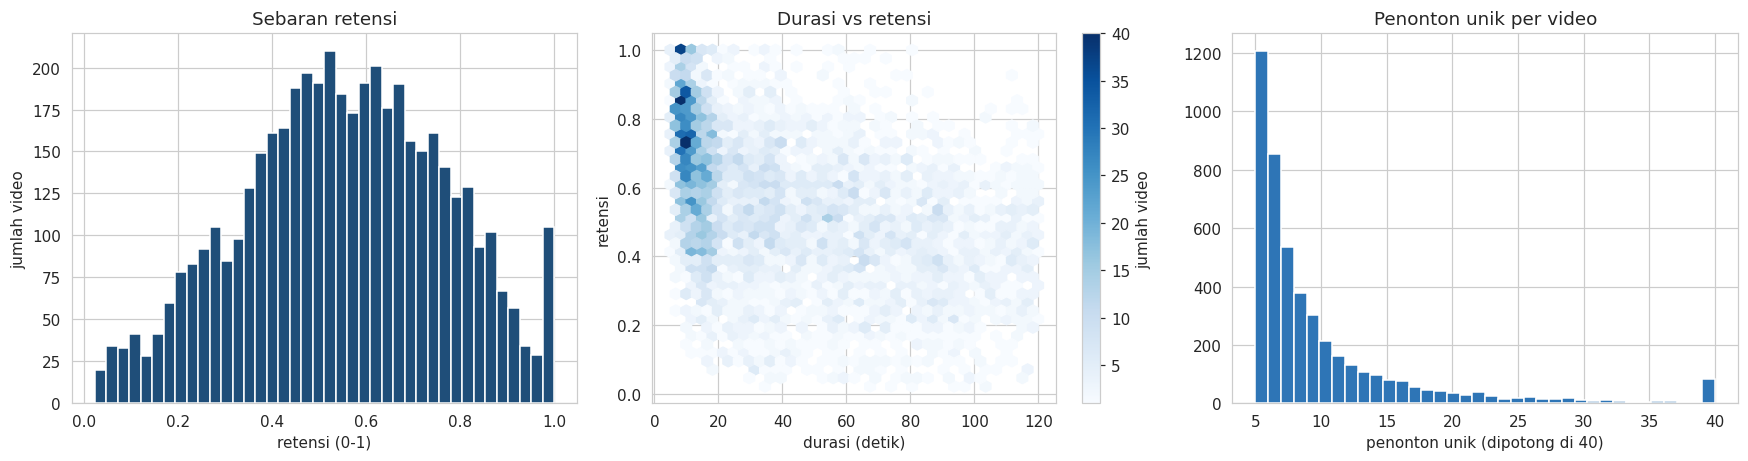

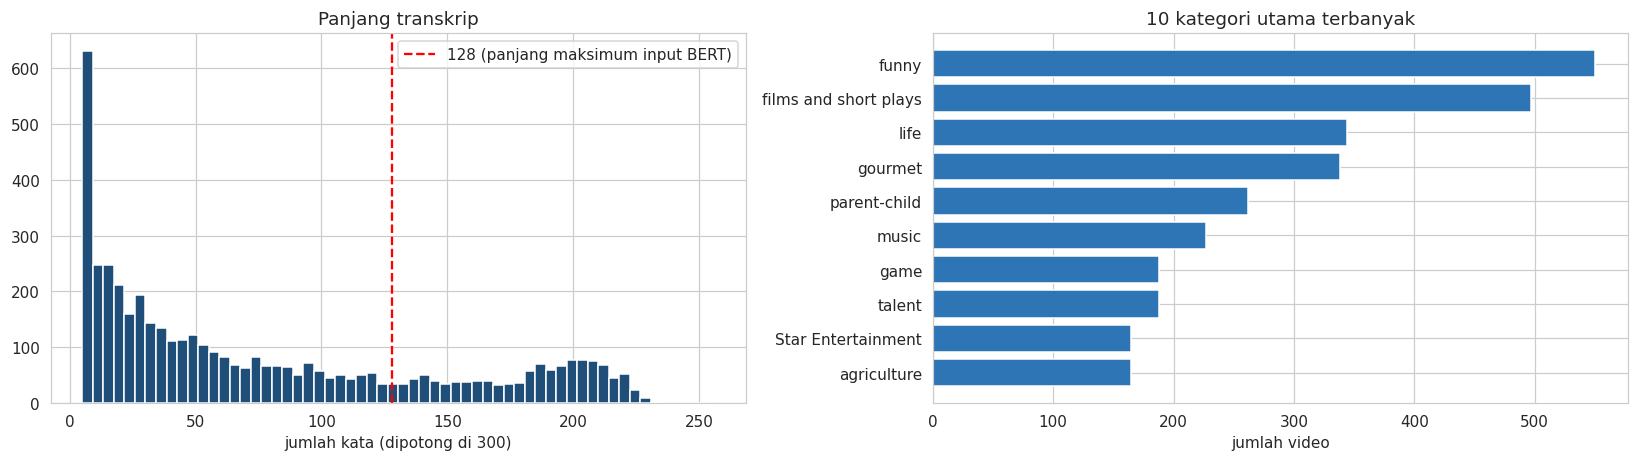

In [24]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
ax[0].hist(gabung['retensi'], bins=40, color='#1F4E79', edgecolor='white')
ax[0].set_title('Sebaran retensi'); ax[0].set_xlabel('retensi (0-1)'); ax[0].set_ylabel('jumlah video')

hb = ax[1].hexbin(gabung['duration'], gabung['retensi'], gridsize=35, cmap='Blues', mincnt=1)
ax[1].set_title('Durasi vs retensi'); ax[1].set_xlabel('durasi (detik)'); ax[1].set_ylabel('retensi')
fig.colorbar(hb, ax=ax[1], label='jumlah video')

ax[2].hist(gabung['n_penonton'].clip(upper=40), bins=36, color='#2E75B6', edgecolor='white')
ax[2].set_title('Penonton unik per video'); ax[2].set_xlabel('penonton unik (dipotong di 40)')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR['random'], 'viz_target_durasi_penonton.png'), dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.3))
ax[0].hist(gabung['word_count'].clip(upper=300), bins=60, color='#1F4E79', edgecolor='white')
ax[0].axvline(128, color='red', linestyle='--', label='128 (panjang maksimum input BERT)')
ax[0].set_title('Panjang transkrip'); ax[0].set_xlabel('jumlah kata (dipotong di 300)'); ax[0].legend()
kat = gabung['category_root_name'].value_counts().head(10)
ax[1].barh(kat.index[::-1], kat.values[::-1], color='#2E75B6')
ax[1].set_title('10 kategori utama terbanyak'); ax[1].set_xlabel('jumlah video')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR['random'], 'viz_teks_kategori.png'), dpi=150, bbox_inches='tight')
plt.show()

---
# TAHAP 8 · Penyimpanan dan Ringkasan

Setiap folder keluaran berisi `train.csv`, `val.csv`, `test.csv`, dan `dataset_full.csv`. Folder
partisi acak juga menyimpan tabel jejak data, struktur kolom, profil statistik, contoh data, dan
gambar. Notebook 02 membaca folder ini sebagai data input.

In [25]:
KOLOM_SIMPAN = ['pid', 'author_id', 'text_clean', 'retensi', 'retensi_adj', 'retensi_tanpa_clip',
                'detik_tonton', 'duration', 'duration_norm', 'n_tayangan', 'n_penonton',
                'pct_tonton_ulang', 'word_count', 'kelompok_panjang', 'category_root_name', 'split']

for mode, (latih, val, uji) in partisi.items():
    for nama, bagian in [('train', latih), ('val', val), ('test', uji)]:
        bagian[KOLOM_SIMPAN].to_csv(os.path.join(OUT_DIR[mode], f'{nama}.csv'), index=False)
    pd.concat([latih, val, uji])[KOLOM_SIMPAN].to_csv(
        os.path.join(OUT_DIR[mode], 'dataset_full.csv'), index=False)
    print(f"{OUT_DIR[mode]}: {sorted(os.listdir(OUT_DIR[mode]))}")

/kaggle/working/final_revisi: ['contoh_data.csv', 'dataset_full.csv', 'jejak_data.csv', 'profil_statistik.csv', 'struktur_kolom.csv', 'test.csv', 'train.csv', 'val.csv', 'viz_target_durasi_penonton.png', 'viz_teks_kategori.png']
/kaggle/working/final_revisi_authorsplit: ['dataset_full.csv', 'test.csv', 'train.csv', 'val.csv']


In [26]:
latih, val, uji = partisi['random']
print("=" * 70)
print("RINGKASAN PRA-PEMROSESAN")
print("=" * 70)
print(f"Data interaksi      : {len(df_interaction):,} baris -> {len(df_int):,} interaksi unik")
print(f"Video akhir         : {len(df):,}")
print(f"Latih / val / uji   : {len(latih):,} / {len(val):,} / {len(uji):,}")
print(f"Penonton unik/video : median {df['n_penonton'].median():.0f}, minimal {df['n_penonton'].min()}")
print(f"Retensi             : rata-rata {df['retensi'].mean():.3f}, median {df['retensi'].median():.3f}")
print(f"Input X             : text_clean (teks), duration_norm (metadata)")
print(f"Target Y            : retensi (utama); retensi_adj dan retensi_tanpa_clip (pembanding)")
print("=" * 70)

RINGKASAN PRA-PEMROSESAN
Data interaksi      : 794,053 baris -> 129,483 interaksi unik
Video akhir         : 4,648
Latih / val / uji   : 3,253 / 697 / 698
Penonton unik/video : median 7, minimal 5
Retensi             : rata-rata 0.552, median 0.553
Input X             : text_clean (teks), duration_norm (metadata)
Target Y            : retensi (utama); retensi_adj dan retensi_tanpa_clip (pembanding)
